# Imports

In [5]:
import numpy as np
import matplotlib
matplotlib.rc_file('C:\\Users\\runner\\matplotlibrc.txt')
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import pandas as pd
from tqdm import tqdm
import subprocess

import os, sys
sys.path.append("D:\\DATA\\ActivePIC")
from pathlib import Path

rsoft_python_paths = [
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\most\python",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\bin",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\python\python3.11\Lib\site-packages"
]
for p in rsoft_python_paths:
    if p not in sys.path:
        sys.path.insert(0, p)
from rstools import RSoftCircuit
import rsoft_lib as rlib

import importlib

# BeamPROP: Scan wavelength

In [22]:
# Define directories and files to work with
device_name_root = "P-10_AchromaticPhaseDelay"
device_name = f"{device_name_root}_a"
working_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\{device_name_root}\\"
mode_dir = f"D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\StraightWaveguide_neff_table\\"
save_dir = f"{working_dir}{device_name}_scan_Wav\\"
os.makedirs(save_dir, exist_ok=True)
CAD_path = f"{working_dir}{device_name}.ind"

# Define parameter scan
wav_arr = np.linspace(1.45, 1.65, 11)
Grid_size, Grid_edge, Step_z = 0.1, 0.1, 0.1

# Run parameter scan
keep_ext = (".mon", ".json", ".dat")
for wav in tqdm(wav_arr, desc='Wavelength loop', position=0, leave=False):
    wav_str = rlib.param_str(wav)
    rlib.run_sim(
        CAD_path,
        prefix=f"{save_dir}{device_name}_scan_Wav{wav_str}",
        symbols={
            "free_space_wavelength": wav,
            "Injection_filename": rlib.mode_field(wav, 3.4)[0],
            "Grid_size": Grid_size,
            "Grid_edge": Grid_edge,
            "Step_z": Step_z,
            "pade_order_warning_3d": 0,
            "pade_order": 4
        },
        keep_ext=keep_ext
    )

np.save(f"{save_dir}{device_name}_Wav.npy", wav_arr)

Wavelength loop:   0%|          | 0/11 [00:00<?, ?it/s]

# Plot APD performance

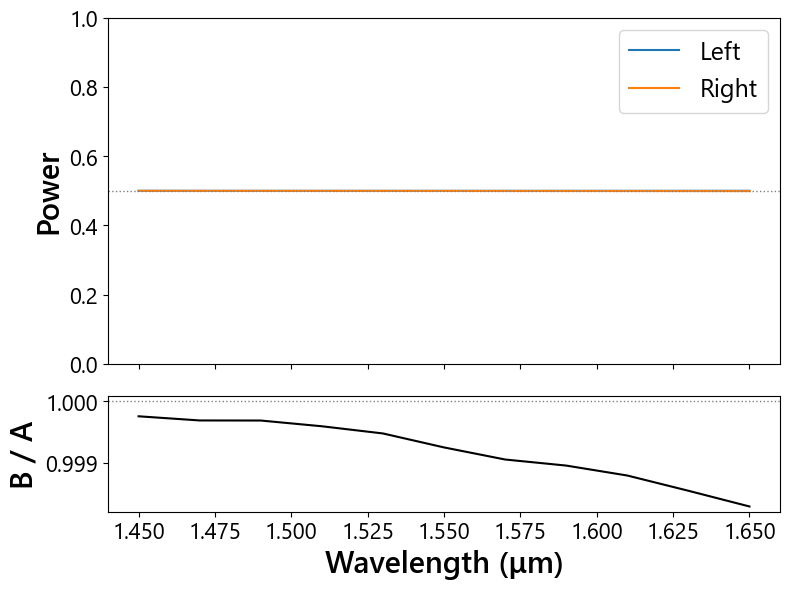

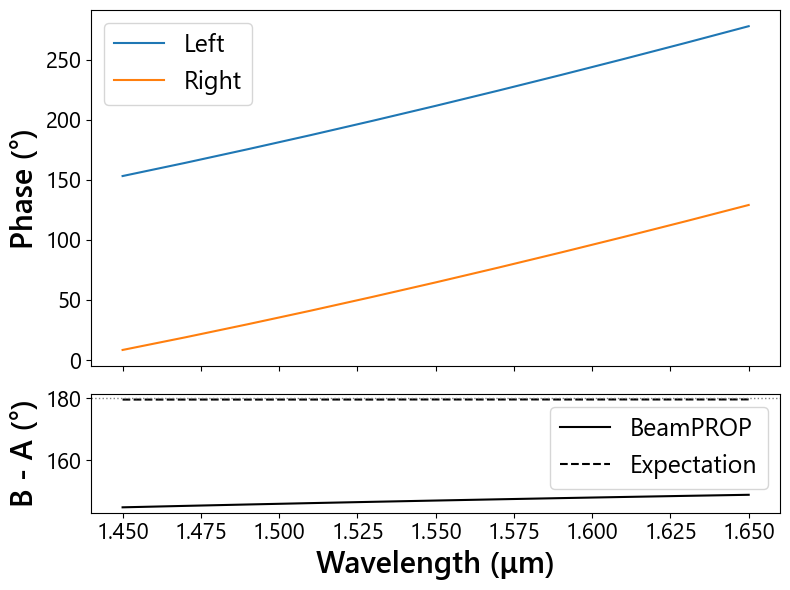

In [12]:
# Hani's reference metrics
reference_arr = 'D:\\DATA\\NullingPIC_Gen2_sims\\P-10_AchromaticPhaseDelay\\apd_v2_for_Nem_Anusha\\a_design4_standard_v2_phase.csv'
df_ref = pd.read_csv(reference_arr)

# BeamPROP metrics (from the scan with rlib.run_sim)
device_name = "P-10_AchromaticPhaseDelay"
working_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\{device_name}\\"
save_dir = f"{working_dir}{device_name}_scan_Wav\\"

wav_arr = np.load(f"{save_dir}{device_name}_Wav.npy")
monitor_arr = np.array([rlib.read_monitor(f"{save_dir}{device_name}_scan_Wav{rlib.param_str(wav)}.mon").values[-1]
                        for wav in wav_arr])          # last z sample: left power, left phase, right power, right phase

# Power
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
ax1.plot(wav_arr, monitor_arr[:, 0], label='Left')
ax1.plot(wav_arr, monitor_arr[:, 2], label='Right')
# ax1.plot(df_ref['wavelength_um'], df_ref['top_power_surrogate'] / 2, linestyle='dashed', color='C0')
# ax1.plot(df_ref['lambda_um'], df_ref['bottom_power_surrogate'] / 2, linestyle='dashed', color='C1')
ax1.axhline(0.5, color='grey', linestyle='dotted', linewidth=1)
ax1.set_ylabel('Power')
ax1.set_ylim(0, 1)
ax1.legend()

residual = monitor_arr[:, 2] / monitor_arr[:, 0]
ax2.plot(wav_arr, residual, color='k')
# ax2.plot(df_ref['lambda_um'], (df_ref['top_power_surrogate'] - df_ref['bottom_power_surrogate']) / df_ref['bottom_power_surrogate'], 'k--')
ax2.axhline(1, color='grey', linestyle='dotted', linewidth=1)
ax2.set_xlabel('Wavelength (μm)')
ax2.set_ylabel('B / A')
plt.tight_layout()
plt.show()

# Phase
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
ax1.plot(wav_arr, monitor_arr[:, 1], label='Left')
ax1.plot(wav_arr, monitor_arr[:, 3], label='Right')
ax1.set_ylabel('Phase (°)')
ax1.legend()

ax2.plot(wav_arr, (monitor_arr[:, 1] - monitor_arr[:, 3]) % 360, color='k', label='BeamPROP')
ax2.plot(df_ref['wavelength_um'], (180 + df_ref['err_bias_0nm_deg']) % 360, 'k--', label='Expectation')
ax2.axhline(180, color='grey', linestyle='dotted', linewidth=1)
ax2.set_xlabel('Wavelength (μm)')
ax2.set_ylabel('B - A (°)')
ax2.legend()
plt.tight_layout()
plt.show()

Coupling length 278: 18 of 45 runs available
Coupling length 308: 0 of 45 runs available
Coupling length 338: 0 of 45 runs available


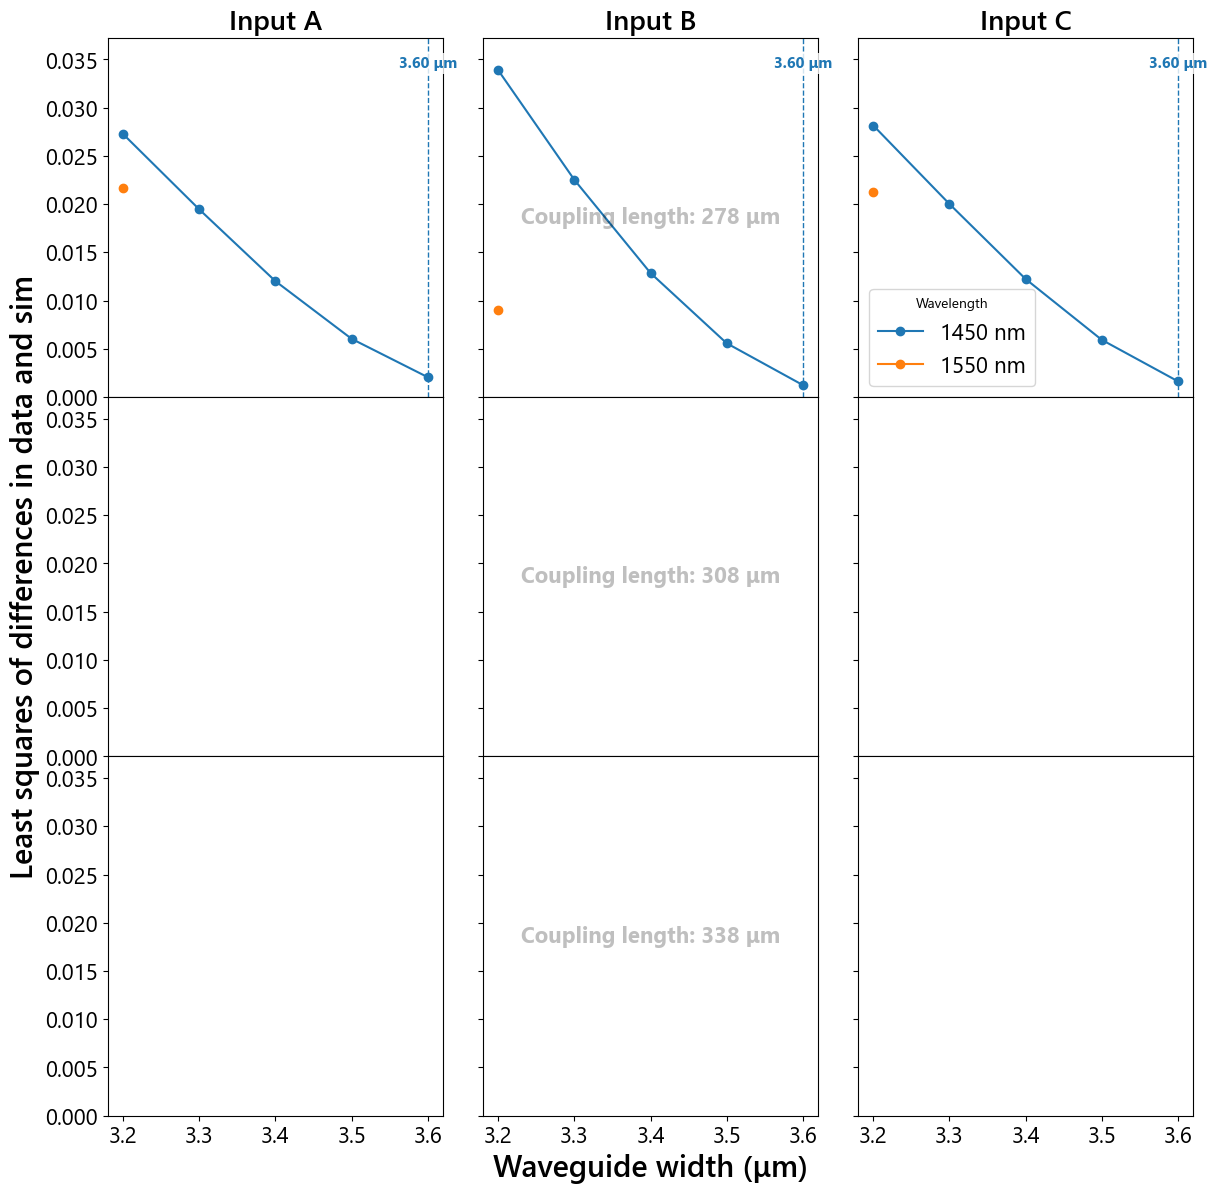


Best width (μm) for each coupling length, input and wavelength ('-' = no minimum found yet in the finished widths)
    L  input     1450     1550     1650
  278      A    3.600        -        -
  278      B    3.600        -        -
  278      C    3.600        -        -
  308      A        -        -        -
  308      B        -        -        -
  308      C        -        -        -
  338      A        -        -        -
  338      B        -        -        -
  338      C        -        -        -


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

import rsoft_lib as rlib

working_dir = "D:\\DATA\\ActivePIC\\Tricoupler\\"
data_dir = f"{working_dir}tricoupler_passive_data\\"                  # measured splitting: Tricoupler_couplingLength{L}_input{A,B,C}.txt
filename_root = "Tricoupler_FiberOneInput"

coupling_lengths = [278, 308, 338]
inputs = ["A", "B", "C"]
target_wavs = [1450, 1550, 1650]                                       # nm; must be among the wavelengths of the scan
widths = np.linspace(3.2, 3.6, 5)                                      # the widths of the scan (the .npy is only saved when a coupling length finishes)


def sim_folder(coupling_length):
    return f"{working_dir}Tricoupler_passive_sim\\{filename_root}_couplingLength{coupling_length}_scan_Wav_Width\\"


def read_sim(coupling_length, input_name, width, wav_um):
    """(fractions of the total power in outputs A, B, C, last z) of one simulation, or None if it has not run."""
    path = (f"{sim_folder(coupling_length)}{filename_root}_couplingLength{coupling_length}_input{input_name}"
            f"_Width{rlib.param_str(width, 2)}_Wav{rlib.param_str(wav_um)}.mon")
    try:
        mon = rlib.read_monitor(path)
    except (OSError, ValueError):
        return None
    power_cols = [i for i, t in enumerate(mon.type) if t == "FILE_POWER"]
    if len(power_cols) != 3:
        raise ValueError(f"Expected 3 power monitors (outputs A, B, C), found the monitor types {mon.type}")
    p = mon.values[-1, power_cols]
    return p / p.sum(), mon.z[-1]


def best_width(w, y):
    """Width at the minimum of the finished points; a parabola through the lowest point and its neighbours refines it.
    A minimum at the end of a scan that is still running is not a minimum yet, so it returns None."""
    ok = np.isfinite(y)
    complete = ok.all()
    w, y = w[ok], y[ok]
    if len(y) < 3:
        return None
    k = int(np.argmin(y))
    if 0 < k < len(y) - 1:
        a, b, _ = np.polyfit(w[k - 1:k + 2], y[k - 1:k + 2], 2)
        if a > 0:
            return -b / (2 * a)
    return w[k] if complete else None


# measured data (read each file once)
data = {(L, name): np.genfromtxt(f"{data_dir}Tricoupler_couplingLength{L}_input{name}.txt", names=True, delimiter=',')
        for L in coupling_lengths for name in inputs}

# simulations that exist so far; a run that stops short in z (still running) is ignored
sims = {}
for L in coupling_lengths:
    found = {}
    for name in inputs:
        for target in target_wavs:
            for i, w in enumerate(widths):
                result = read_sim(L, name, w, target / 1000)
                if result is not None:
                    found[(name, target, i)] = result
    if found:
        z_max = max(z for _, z in found.values())
        found = {k: f for k, (f, z) in found.items() if z > z_max - 1.0}
    sims.update({(L,) + k: f for k, f in found.items()})
    print(f"Coupling length {L}: {len(found)} of {len(inputs) * len(target_wavs) * len(widths)} runs available")

# least squares of the difference in splitting fractions, for every width that has run
lsq = {}
for L in coupling_lengths:
    for name in inputs:
        for target in target_wavs:
            row = data[(L, name)][np.isclose(data[(L, name)]['wav'], target, atol=0.1)]
            measured = np.array([row['outputA'][0], row['outputB'][0], row['outputC'][0]])
            measured = measured / measured.sum()
            lsq[(L, name, target)] = np.array([np.sum((sims[(L, name, target, i)] - measured) ** 2)
                                               if (L, name, target, i) in sims else np.nan for i in range(len(widths))])
if not any(np.isfinite(y).any() for y in lsq.values()):
    raise RuntimeError("No finished simulations found yet.")

# plot
ymax = 1.1 * max(np.nanmax(y) for y in lsq.values() if np.isfinite(y).any())
fig, ax = plt.subplots(3, 3, figsize=(14, 14), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.12, hspace=0)
best = {}
for row_i, L in enumerate(coupling_lengths):
    for col, name in enumerate(inputs):
        for i_wav, target in enumerate(target_wavs):
            y = lsq[(L, name, target)]
            if not np.isfinite(y).any():
                continue
            line, = ax[row_i, col].plot(widths, y, 'o-', color=f'C{i_wav}', label=f'{target} nm')
            w_best = best_width(widths, y)
            best[(L, name, target)] = w_best
            if w_best is not None:                                      # needs a minimum inside the finished widths
                ax[row_i, col].axvline(w_best, linestyle='--', linewidth=1, color=line.get_color())
                ax[row_i, col].text(w_best, 0.95 - 0.09 * i_wav, f'{w_best:.2f} μm', transform=ax[row_i, col].get_xaxis_transform(),
                                    ha='center', va='top', color=line.get_color(), fontsize=11, fontweight='bold',
                                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=2))
        ax[row_i, col].set(ylim=(0, ymax))
        ax[row_i, col].set_xticks(widths)
    ax[row_i, 1].text(0.5, 0.5, f'Coupling length: {L} μm', transform=ax[row_i, 1].transAxes, ha='center', va='center',
                      fontsize=16, fontweight='bold', alpha=0.25)
for col, name in enumerate(inputs):
    ax[0, col].set_title(f'Input {name}')
ax[0, 2].legend(fontsize=16, title='Wavelength')
ax[2, 1].set_xlabel('Waveguide width (μm)')
ax[1, 0].set_ylabel('Least squares of differences in data and sim')
plt.show()

print("\nBest width (μm) for each coupling length, input and wavelength ('-' = no minimum found yet in the finished widths)")
print(f"{'L':>5s}{'input':>7s}" + "".join(f"{t:>9d}" for t in target_wavs))
for L in coupling_lengths:
    for name in inputs:
        print(f"{L:5d}{name:>7s}" + "".join(f"{best[(L, name, t)]:9.3f}" if best.get((L, name, t)) is not None else f"{'-':>9s}" for t in target_wavs))